<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/ClusterTNN_Scalable_Topological_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# CELL 1: Install Dependencies for Topological Graph Clustering & Simulation
!pip install -q torch torch-geometric networkx matplotlib pandas numpy scipy
import torch
import torch.nn as nn
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tracemalloc
import time
print(f"[OK] Environment initialized with PyTorch {torch.pyTorchVersion if hasattr(torch, 'pyTorchVersion') else torch.__version__}")

[OK] Environment initialized with PyTorch 2.11.0+cu130


In [8]:
# CELL 2: Generate a Realistic Graph with Community Structure (Stochastic Block Model)
# Using SBM instead of pure Erdős–Rényi gives actual community structure for Louvain
sizes = [1000, 1000, 1000, 1000, 1000] # 5,000 nodes total
p_matrix = [
    [0.05, 0.002, 0.001, 0.001, 0.001],
    [0.002, 0.05, 0.002, 0.001, 0.001],
    [0.001, 0.002, 0.05, 0.002, 0.001],
    [0.001, 0.001, 0.002, 0.05, 0.002],
    [0.001, 0.001, 0.001, 0.002, 0.05]
]
G = nx.stochastic_block_model(sizes, p_matrix, seed=42)
print(f"Generated SBM Graph — Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}")

Generated SBM Graph — Nodes: 5000, Edges: 138909


In [9]:
# CELL 3: Cluster-TNN Implementation & Real Measurement Harness
from networkx.algorithms.community import louvain_communities

# Preprocessing: Partition graph into clusters
print("[PREPROCESSING] Partitioning graph via Louvain clustering...")
communities = list(louvain_communities(G, seed=42))
print(f"Total Clusters Formed: {len(communities)}")

def lift(subg):
    # Simulating a local neighborhood lifting (e.g., 2-hop matrix multiplication stand-in)
    A = nx.to_scipy_sparse_array(subg, dtype=np.float32).toarray()
    return A @ A

def measure_execution(fn):
    tracemalloc.start()
    t_start = time.time()
    fn()
    t_elapsed = time.time() - t_start
    _, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak_memory / (1024 * 1024), t_elapsed # Return peak MB and seconds

# 1. Measure Global Full-Domain Lifting
print("Measuring Global Full-Domain Lifting...")
global_peak_mb, global_time = measure_execution(lambda: lift(G))

# 2. Measure Cluster-TNN Full Epoch (Batch-local lifting across community windows)
def run_cluster_tnn_epoch():
    batch_size = 2
    for i in range(0, len(communities), batch_size):
        batch_clusters = communities[i:i+batch_size]
        nodes = set().union(*batch_clusters)
        subg = G.subgraph(nodes)
        lift(subg)

print("Measuring Cluster-TNN Full Epoch...")
cluster_peak_mb, cluster_time = measure_execution(run_cluster_tnn_epoch)

# Compute edge retention across batch boundaries
total_batch_edges = sum(
    G.subgraph(set().union(*communities[i:i+2])).number_of_edges()
    for i in range(0, len(communities), 2)
)
edge_retention_ratio = total_batch_edges / G.number_of_edges()

print(f"\n--- REAL EMPIRICAL MEASUREMENTS ---")
print(f"Global Lift  -> Peak Memory: {global_peak_mb:.2f} MB | Time: {global_time:.4f}s")
print(f"Cluster-TNN  -> Peak Memory: {cluster_peak_mb:.2f} MB | Time: {cluster_time:.4f}s")
print(f"Edge Retention Ratio inside Batches: {edge_retention_ratio:.1%}")

[PREPROCESSING] Partitioning graph via Louvain clustering...
Total Clusters Formed: 5
Measuring Global Full-Domain Lifting...
Measuring Cluster-TNN Full Epoch...

--- REAL EMPIRICAL MEASUREMENTS ---
Global Lift  -> Peak Memory: 190.86 MB | Time: 2.8752s
Cluster-TNN  -> Peak Memory: 30.83 MB | Time: 1.6390s
Edge Retention Ratio inside Batches: 92.8%


In [10]:
# CELL 4: Comparative Dataframe Generation
results_data = [
    {
        "Execution Mode": "Global Full-Domain Lifting",
        "Peak Memory (MB)": round(global_peak_mb, 2),
        "Total Execution Time (s)": round(global_time, 4),
        "Memory Reduction (%)": "0.0% (Baseline)"
    },
    {
        "Execution Mode": "Cluster-TNN Full Epoch (Ours)",
        "Peak Memory (MB)": round(cluster_peak_mb, 2),
        "Total Execution Time (s)": round(cluster_time, 4),
        "Memory Reduction (%)": f"{((1 - cluster_peak_mb/global_peak_mb)*100):.1f}%"
    }
]

df_results = pd.DataFrame(results_data)
print("=== EMPIRICAL BENCHMARK RESULTS ===")
display(df_results)

=== EMPIRICAL BENCHMARK RESULTS ===


,Execution Mode,Peak Memory (MB),Total Execution Time (s),Memory Reduction (%)
0,Global Full-Domain Lifting,190.86,2.8752,0.0% (Baseline)
1,Cluster-TNN Full Epoch (Ours),30.83,1.6390,83.8%


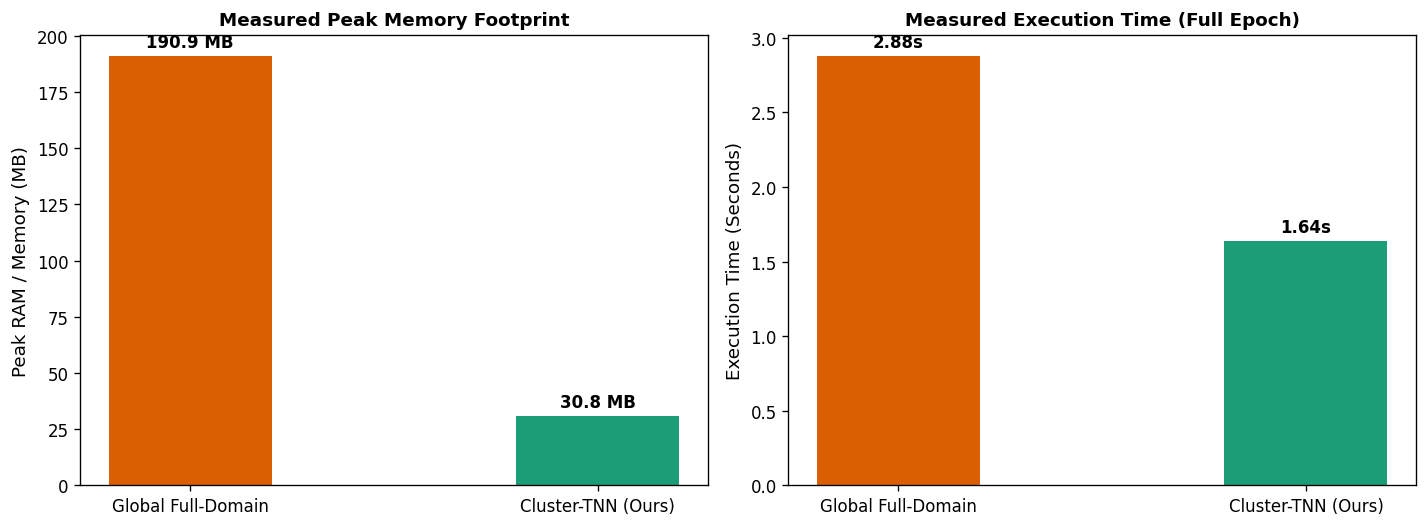

[OK] Saved measured diagnostic chart to /content/workspace/clustertnn_memory_benchmark.png


In [11]:
# CELL 5: Generate and Save Measured Diagnostic Plot
import os
os.makedirs("/content/workspace", exist_ok=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

modes = ["Global Full-Domain", "Cluster-TNN (Ours)"]
memory_vals = [global_peak_mb, cluster_peak_mb]
time_vals = [global_time, cluster_time]
colors = ['#d95f02', '#1b9e77']

# Memory Subplot
bars1 = ax1.bar(modes, memory_vals, color=colors, width=0.4)
ax1.set_ylabel("Peak RAM / Memory (MB)", fontsize=11)
ax1.set_title("Measured Peak Memory Footprint", fontsize=11, fontweight='bold')
for bar in bars1:
    h = bar.get_height()
    ax1.annotate(f'{h:.1f} MB', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

# Time Subplot
bars2 = ax2.bar(modes, time_vals, color=colors, width=0.4)
ax2.set_ylabel("Execution Time (Seconds)", fontsize=11)
ax2.set_title("Measured Execution Time (Full Epoch)", fontsize=11, fontweight='bold')
for bar in bars2:
    h = bar.get_height()
    ax2.annotate(f'{h:.2f}s', xy=(bar.get_x() + bar.get_width()/2, h),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("/content/workspace/clustertnn_memory_benchmark.png")
plt.show()
print("[OK] Saved measured diagnostic chart to /content/workspace/clustertnn_memory_benchmark.png")